# Train — ResNet-18 (scratch)

Trains and evaluates ResNet-18 **without ImageNet pretraining and without tuning** (`NO_TUNING_ARCH_HYPERPARAMS["resnet18"]`), then saves its results and weights to disk for the results notebook. This is the baseline role AlexNet used to play — see `wwtw_utils.py`'s `ARCH_HYPERPARAMS` comment for why the baseline is now the *same* architecture as the tuned, pretrained `resnet18` run rather than a different one.


In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID (derived from DATASET_ROOT): CapeFlats
Train-time augmentation: on
Classes found (3): ['Dysfunctional', 'Functional', 'Suboptimal']
Train: 785 | Val: 192 | Test: 766


## Build dataloaders + class weights for this architecture

In [2]:
cfg = NO_TUNING_ARCH_HYPERPARAMS["resnet18"]

# The tuned batch size (cfg["batch_size"]) can be too large to fit in GPU
# memory for a deeper model like this one, even though it fit fine for
# whichever model the tuning trials actually ran on. Rather than hard-coding
# a smaller batch size (and drifting from the tuned hyperparameters), cap the
# *actual* loader batch size at MICRO_BATCH_CAP and use gradient accumulation
# in train_model to still reach the tuned effective batch size.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18: micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, tuned value = {cfg['batch_size']})")

# This backbone gets its own dataloaders, same as every other architecture
# here -- its own (capped) batch size and image size, per cfg.
train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18: micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, tuned value = 32)


## Define the model (ResNet-18, trained from scratch)

In [3]:
# ---------------------------------------------------------
# Define the CNN (ResNet-18, trained from scratch — no ImageNet weights)
# ---------------------------------------------------------
model = models.resnet18(weights=None)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
# Step-based decay: LR x0.1 every Es epochs, per the tuned step size.
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train, then plot training curves

[ResNet-18 (scratch)] Using gradient accumulation: 2 micro-batches per optimizer step (effective batch size ≈ micro_batch x 2).


[ResNet-18 (scratch)] Epoch   1/100 | LR: 1.00e-04 | train loss 1.0561 acc 0.487 | val loss 1.0119 acc 0.547 *


[ResNet-18 (scratch)] Epoch   2/100 | LR: 1.00e-04 | train loss 0.9920 acc 0.582 | val loss 0.8685 acc 0.604 *


[ResNet-18 (scratch)] Epoch   3/100 | LR: 1.00e-04 | train loss 0.9934 acc 0.550 | val loss 0.7793 acc 0.646 *


[ResNet-18 (scratch)] Epoch   4/100 | LR: 1.00e-04 | train loss 0.9778 acc 0.605 | val loss 0.9078 acc 0.615


...

[ResNet-18 (scratch)] Epoch  48/100 | LR: 1.00e-07 | train loss 0.7610 acc 0.690 | val loss 0.5635 acc 0.740


[ResNet-18 (scratch)] Epoch  49/100 | LR: 1.00e-07 | train loss 0.7810 acc 0.667 | val loss 0.5487 acc 0.755


[ResNet-18 (scratch)] Epoch  50/100 | LR: 1.00e-07 | train loss 0.7355 acc 0.710 | val loss 0.5451 acc 0.781


[ResNet-18 (scratch)] Epoch  51/100 | LR: 1.00e-07 | train loss 0.7611 acc 0.682 | val loss 0.5469 acc 0.776


[ResNet-18 (scratch)] Epoch  52/100 | LR: 1.00e-07 | train loss 0.7992 acc 0.671 | val loss 0.5544 acc 0.755

[ResNet-18 (scratch)] No val loss improvement for 10 epochs — stopping early at epoch 52.

[ResNet-18 (scratch)] Restored best checkpoint (val loss = 0.5402)


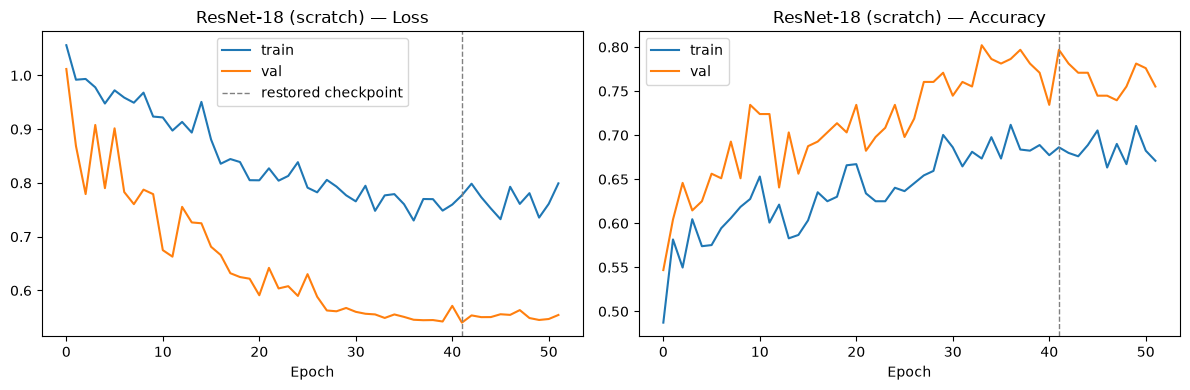

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18 (scratch)", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18 (scratch)")

## Evaluate on the test set

[ResNet-18 (scratch)] Test accuracy: 0.210


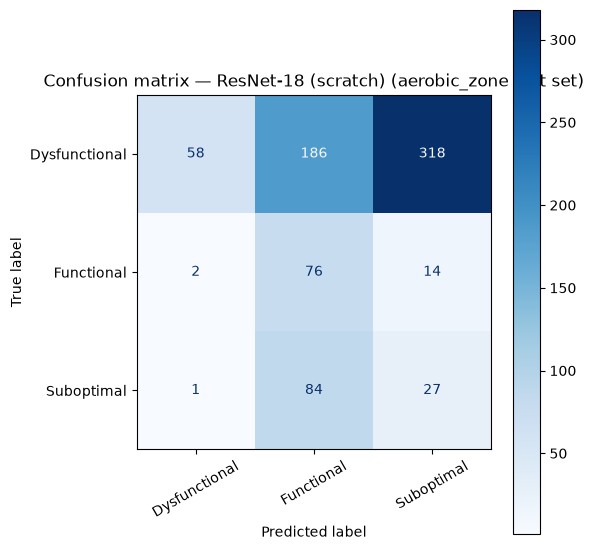

               precision    recall  f1-score   support

Dysfunctional      0.951     0.103     0.186       562
   Functional      0.220     0.826     0.347        92
   Suboptimal      0.075     0.241     0.115       112

     accuracy                          0.210       766
    macro avg      0.415     0.390     0.216       766
 weighted avg      0.735     0.210     0.195       766



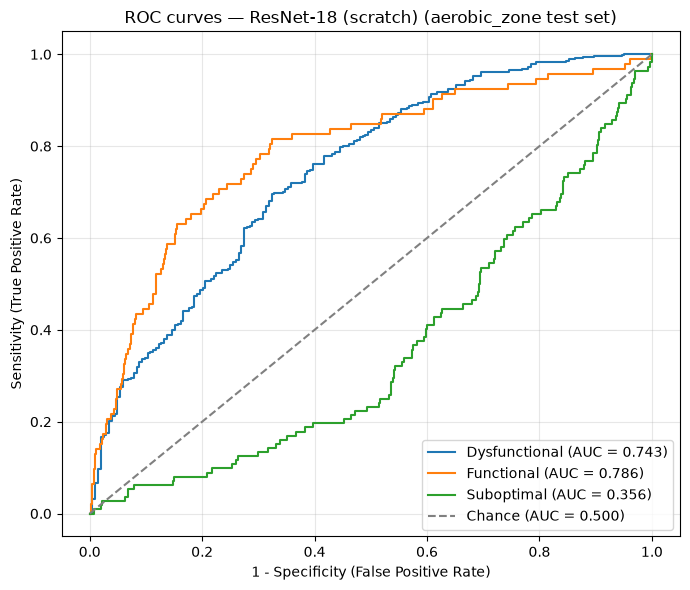

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.743
  Functional     : 0.786
  Suboptimal     : 0.356

Mean AUC (over 3/3 classes with test examples): 0.628


(np.float64(0.21018276762402088),
 {'Dysfunctional': 0.7430657316307305,
  'Functional': 0.7856405625080635,
  'Suboptimal': 0.35555919615552645})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18 (scratch)", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
)

## Save results + model weights to disk

This is the step the results notebook depends on — it pickles the metrics/history and saves the model state dict so nothing needs to be kept in memory or re-trained.

In [6]:
save_result("ResNet-18 (scratch)", "resnet18_scratch")

Saved results to ../results/aerobic_zone_aug/results_aerobic_zone_resnet18_scratch_CapeFlats.pkl
Saved model weights to ../models/pad/aerobic_zone_resnet18_scratch_cnn.pt
